<h3 style="text-align: center;"><b> Занятие 2. Библиотеки NumPy, Pandas, Matplotlib </b></h3>


На этом занятии мы познакомимся с NumPy, а затем научимся проводить первичный анализ и визуализацию данных при помощи библиотек Pandas и Matplotlib. Мы будем работать с датасетом [Titanic](https://www.kaggle.com/competitions/titanic/overview).

https://github.com/datasciencedojo/datasets/blob/master/titanic.csv - ссылка на гитхаб, где можно скачать данные.

**План занятия:**
* Знакомство с NumPy
  * Кратко о np.linalg

* Работа с данными
  * Загрузка данных Titanic
  * Описание данных
  * Знакомство с данными и введение в pandas
  * Агрегационные функции и группировка данных

* Анализ и визуализация данных

* Подготовка данных
  * Разделение на train/test
  * Масштабирование признаков

* Новый датасет: линейная модель, анализ признаков и CSV


## Знакомство с NumPy

Для начала давайте познакомимся с библиотекой **NumPy** (Numerical Python). Это фундаментальная библиотека Python для научных вычислений. Она предоставляет мощные инструменты для работы с многомерными массивами и матрицами, а также включает большое количество математических функций для операций над ними.

Зачем нужен NumPy? Потому что стандартные списки python медленны и неудобны для математических операций над большими объёмами данных. NumPy решает эту проблему:

- Скорость: операции выполняются на C, что в десятки раз быстрее чистого Python.
- Память: массивы NumPy занимают меньше памяти, чем списки.
- Удобство: векторные операции позволяют писать код без циклов.
- Экосистема: на NumPy построены SciPy, Pandas, Matplotlib, scikit-learn и другие.

### Массив NumPy и обычный список

NumPy обычно импортируется как `np`

In [373]:
import numpy as np

Основная структура данных в NumPy — **`ndarray`**, или многомерный массив. Одномерный массив можно представить как ряд чисел, двумерный — как таблицу со строками и столбцами.

In [374]:
values_list = [15, 1, 2, 4, 3, 0]
values = np.array(values_list)

In [375]:
values.argsort()

array([5, 1, 2, 4, 3, 0])

С такими массивами можно работать в векторном виде, что сильно упрощает написание кода

### Зачем нужен NumPy: сравним скорость

Представим, что нам нужно проделать одинаковую арифметическую операцию с каждым числом списка. Для списка придется применить формулу к каждому элементу с помощью цикла. Для массива достаточно записать саму формулу.

In [376]:
a_list = [i for i in range(10)]
a = np.array(a_list)

In [377]:
updated_list = [value * 3 + 2 for value in a_list]
updated_array = a * 3 + 2

assert np.allclose(updated_list, updated_array)

Такой способ записи вычислений над массивом называется **векторизацией**. Мы описываем операцию сразу для всех элементов, а перебор выполняется внутри NumPy в скомпилированном коде. Числовые массивы хранят значения одного типа, что позволяет обрабатывать их эффективно.

`np.allclose()` проверяет, что все соответствующие числа близки с учетом небольшой погрешности. Это удобно для дробных чисел: из-за их представления в памяти точное равенство не всегда подходит.

На пяти значениях разницу во времени заметить сложно. Давайте повторим наши пять чисел 200 000 раз и получим миллион значений. Подготовим список и массив **до замера**, чтобы сравнивать именно вычисления:

In [378]:
large_values_list = a_list * 200_000
large_values_array = np.array(large_values_list, dtype=np.float64)

def update_with_list():
    return [value * 1.1 + 2 for value in large_values_list]

def update_with_numpy():
    return large_values_array * 1.1 + 2

assert np.allclose(update_with_list(), update_with_numpy())

На большом числовом массиве разница обычно хорошо заметна. Конкретные времена и ускорение зависят от компьютера, его загрузки и версии библиотек — у вас числа могут отличаться.

(!) В этом примере список и массив уже готовы к работе. Преобразование списка в массив тоже занимает время. Для нескольких чисел или одной простой операции оно может свести выигрыш на нет. NumPy особенно полезен, когда мы много раз обрабатываем большие числовые массивы.

### Форма, размерность и тип данных

Теперь создадим двумерный массив из чисел: в нем будет три строки и два столбца.

In [379]:
values = np.array([1, 2, 3, 4, 5])

matrix = np.array([
    [22, 7.25],
    [38, 71.28],
    [26, 7.92],
])

In [380]:
print(values.__doc__)

ndarray(shape, dtype=None, buffer=None, offset=0, strides=None, order=None)
--

ndarray(shape, dtype=np.float64, buffer=None, offset=0, strides=None, order=None)

An array object represents a multidimensional, homogeneous array
of fixed-size items.  An associated data-type object describes the
format of each element in the array (its byte-order, how many bytes it
occupies in memory, whether it is an integer, a floating point number,
or something else, etc.)

Arrays should be constructed using `array`, `zeros` or `empty` (refer
to the See Also section below).  The parameters given here refer to
a low-level method (`ndarray(...)`) for instantiating an array.

For more information, refer to the `numpy` module and examine the
methods and attributes of an array.

Parameters
----------
(for the __new__ method; see Notes below)

shape : tuple of ints
    Shape of created array.
dtype : data-type, optional
    Any object that can be interpreted as a numpy data type.
    Default is `numpy.float

* **`ndim`** — количество измерений, или осей. У нашего массива две оси: строки и столбцы.
* **`shape`** — размер по каждой оси. Здесь `(3, 2)` означает 3 строки и 2 столбца. Форма `(5,)` у массива `values` означает одно измерение с 5 элементами, а не таблицу из одного столбца.
* **`size`** — общее количество элементов. В таблице их `3 * 2 = 6`.
* **`dtype`** — тип данных элементов. В отличие от списка, у массива один общий тип. Поэтому целые числа в нашей таблице тоже стали дробными.

Часто мы будем встречать целые числа (`int64`), дробные числа (`float64`) и логические значения (`bool`). Тип можно задать при создании через `dtype` или преобразовать методом `.astype()`:

In [381]:
integer_values = np.array([22, 38, 26], dtype=np.int64)
float_values = integer_values.astype(np.float64)
mixed_numbers = np.array([1, 2.5, 3])

# какой тип будет у mixed_numbers?

### Как создавать массивы

Не всегда удобно перечислять все значения вручную. Для этого есть готовые функции:

* `np.zeros()` и `np.ones()` — массивы из нулей и единиц;
* `np.full()` — массив, заполненный заданным значением;
* `np.arange(start, stop, step)` — последовательность с заданным шагом, **не включая** `stop`;
* `np.linspace(start, stop, num)` — `num` равномерно расположенных точек, по умолчанию **включая оба конца** отрезка.

Если нужен дробный шаг и известно количество точек, удобно использовать `linspace()`.

In [382]:
# показать пример
# [TODO] добавить задачку на это

Для учебных примеров и экспериментов часто нужны случайные числа. Создадим генератор через `np.random.default_rng()` и передадим ему **seed** — начальное значение `42`.

Если заново создать генератор с тем же seed в том же окружении и вызвать те же методы в том же порядке, мы получим ту же последовательность. Это помогает воспроизводить эксперименты. Повторные вызовы методов без пересоздания генератора дают следующие числа последовательности.

In [383]:
rng = np.random.default_rng(4)

print(rng.integers(1, 81, size=5))
print(rng.random((2, 3)))
print(rng.normal(loc=0, scale=1, size=5))

[59 76 71 41 76]
[[0.08083602 0.60735583 0.37648658]
 [0.80190121 0.17452782 0.87163527]]
[0.24177188 0.23538092 1.57562603 0.31664502 0.51054666]


### Индексы, срезы и копии

Как и в списках Python, нумерация начинается с 0, отрицательный индекс отсчитывается с конца, а правая граница среза не включается. В записи `[start:stop:step]` можно задать еще и шаг:

In [384]:
# examples

In [385]:
# task:
# Реализуйте функцию, которая на вход принимает вектор x, а возвращает вектор со вставленными нулями между числами.
# Например, из [2, 6, -1, 8] получить [2, 0, 6, 0, -1, 0, 8]

В двумерном массиве индексы строки и столбца указываются через запятую: `[строка, столбец]`. Двоеточие `:` позволяет выбрать все элементы вдоль нужной оси:

In [386]:
# task: сгенерировать массив размерности (3, 4) случайных целых чисел из промежутка от 0 до 10 и вывести второй столбец массива

(!) Важное отличие от списков: обычный срез массива NumPy возвращает **представление (view)** — новый объект, который ссылается на те же данные. Если изменить такой срез, изменится и исходный массив.

In [387]:
example_values = np.array([1, 2, 3, 4, 5])

first_two = example_values[:2]
first_two[1] = 99

print(first_two)
print(example_values)

[ 1 99]
[ 1 99  3  4  5]


Если нужна независимая копия, воспользуемся методом `.copy()`:

In [388]:
example_values = np.array([1, 2, 3, 4, 5])
first_two_copy = example_values[:2].copy()
first_two_copy[1] = 99

print(first_two_copy)
print(example_values)

[ 1 99]
[1 2 3 4 5]


### Фильтрация по условию

Сравнение массива с числом возвращает **булеву маску** — массив из `True` и `False`. Если передать эту маску в квадратные скобки, останутся только элементы, для которых условие выполняется:

In [389]:
mask = values >= 2

In [390]:
example_values[mask]

array([2, 3, 4, 5])

Несколько условий соединяются через `&` («и») и `|` («или»), а `~` означает отрицание. Каждое сравнение нужно заключать в скобки. Обычные Python-операторы `and` и `or` для таких массивов не подходят.

In [391]:
example_values[(example_values < 2) | (example_values > 0)]

array([1, 2, 3, 4, 5])

Можно также создать новый массив значений по условию. Функция `np.where(условие, значение_если_да, значение_если_нет)` выбирает результат для каждого элемента.

In [392]:
np.where(values < 3, example_values * 0.5, example_values)

array([0.5, 1. , 3. , 4. , 5. ])

### Основные статистики и оси

Теперь посчитаем несколько характеристик нашего массива чисел. Функции NumPy позволяют сразу получить сумму, среднее, минимум и максимум, не перебирая значения вручную.

Медиана — значение посередине отсортированного набора (для четного количества берется среднее двух центральных). Стандартное отклонение характеризует разброс чисел относительно среднего. Квантили делят упорядоченные данные на части; они помогают описать распределение значений.

In [393]:
values = np.linspace(0, 24, num=8, endpoint=False, dtype=int)
print(values)
print(np.sum(values))
print(np.mean(values))
print(np.median(values))
print(np.min(values), np.max(values))
print(np.std(values))
print(np.quantile(values, [0.25, 0.5, 0.75]))

[ 0  3  6  9 12 15 18 21]
84
10.5
10.5
0 21
6.87386354243376
[ 5.25 10.5  15.75]


Многие функции доступны и как методы массива: например, `decimal_values.mean()` и `np.mean(decimal_values)` дадут один результат. У `np.std()` по умолчанию сумма квадратов отклонений делится на количество элементов `N`; для деления на `N - 1` можно передать `ddof=1`.

А что делать с двумерным массивом? Для этого есть параметр **`axis`**. Возьмем массив из двух строк и трех столбцов.

* Без `axis` посчитаем сумму всех элементов.
* При `axis=0` свернем ось строк и получим сумму **для каждого столбца**.
* При `axis=1` свернем ось столбцов и получим сумму **для каждой строки**.

In [394]:
matrix_for_sum = np.array([
    [10, 20, 30],
    [15, 25, 35],
])

print(matrix_for_sum.sum())
print(matrix_for_sum.sum(axis=0))
print(matrix_for_sum.sum(axis=1))

135
[25 45 65]
[60 75]


### Изменение формы массива

Метод `.reshape()` позволяет по-другому расположить те же элементы. Их общее количество должно сохраниться: из 12 чисел можно сделать таблицу 3 на 4, но не 3 на 5. Одну из размерностей можно задать как `-1` — NumPy вычислит ее сам.

Атрибут `.T` у двумерного массива меняет местами строки и столбцы. Это называется **транспонированием**.

In [395]:
numbers = np.arange(12)
number_table = numbers.reshape(3, 4)

print(numbers)
print('-----')
print(number_table)
print('-----')
print(numbers.reshape(-1, 4))
print('-----')
print(number_table.T.shape)
print('-----')
print(number_table.T)

[ 0  1  2  3  4  5  6  7  8  9 10 11]
-----
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
-----
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
-----
(4, 3)
-----
[[ 0  4  8]
 [ 1  5  9]
 [ 2  6 10]
 [ 3  7 11]]


### Операции с массивами и broadcasting

Мы уже умножали весь массив на одно число. NumPy также умеет выполнять некоторые операции с массивами разной формы. Это называется **broadcasting** (распространение).

Давайте вычтем из каждого столбца его среднее значение. У нашей таблицы форма `(3, 2)`, а у средних по столбцам — `(2,)`. NumPy применит одну и ту же пару средних к каждой строке:

In [396]:
column_means = matrix.mean(axis=0)
centered_matrix = matrix - column_means

При broadcasting размеры сравниваются **справа налево**. В каждой паре они должны совпадать или один из них должен быть равен 1; недостающие измерения считаются равными 1. Поэтому `(3, 2)` и `(2,)` совместимы, а `(3, 2)` и `(3,)` — нет. Чтобы применить отдельное число к каждой строке таблицы из 3 строк, массив из 3 чисел можно превратить в столбец через `.reshape(3, 1)`.

Еще одно различие: `*` умножает элементы по отдельности, а `@` выполняет матричное умножение. Например, возьмем таблицу из двух строк и трех столбцов и одномерный массив из трех чисел. Через `*` умножим каждый столбец таблицы на соответствующее число. Через `@` дополнительно сложим полученные произведения в каждой строке — результатом будет массив из двух чисел:

In [397]:
multipliers = np.array([100, 50, 20])

print(matrix_for_sum * multipliers)
print(matrix_for_sum @ multipliers)

[[1000 1000  600]
 [1500 1250  700]]
[2600 3450]


### Еще несколько полезных функций

Математические функции тоже работают поэлементно.

In [398]:
arr = np.arange(3, 30, 5)
float_arr = rng.uniform(size=10)
print(np.sqrt([1, 4, 9, 16]))
print(np.log(arr))
print(np.round(float_arr, 2))
print(np.clip([-0.2, 0.3, 0.8, 1.4], 0, 1))

[1. 2. 3. 4.]
[1.09861229 2.07944154 2.56494936 2.89037176 3.13549422 3.33220451]
[0.98 0.37 0.97 0.93 0.18 0.61 0.7  0.94 0.67 0.13]
[0.  0.3 0.8 1. ]


Для сортировки есть `np.sort()`: она возвращает отсортированную копию массива. Функция `np.unique()` находит уникальные значения, а с параметром `return_counts=True` еще и считает, сколько раз каждое значение встретилось. Давайте посмотрим на примере массива с повторяющимися числами:

In [399]:
repeated_values = np.array([3, 1, 3, 1, 2, 3])
unique_values, counts = np.unique(repeated_values, return_counts=True)

Если данные пришли несколькими частями, их можно объединить. `np.concatenate()` соединяет массивы вдоль существующей оси, а `np.stack()` добавляет новую ось. Например, из двух одномерных массивов получим либо один длинный массив, либо таблицу:

In [400]:
first_array = np.array([1, 2, 3])
second_array = np.array([4, 5, 6])

print(np.concatenate([first_array, second_array]))
print(np.stack([first_array, second_array]))
print(np.stack([first_array, second_array], axis=1))

[1 2 3 4 5 6]
[[1 2 3]
 [4 5 6]]
[[1 4]
 [2 5]
 [3 6]]


В реальных данных бывают пропуски. В числовом массиве их часто обозначают как **`np.nan`** (Not a Number).

Чтобы найти пропуски, используется `np.isnan()`, а чтобы посчитать среднее без них — `np.nanmean()`. Сравнение `значение == np.nan` для поиска пропусков не подходит.

In [401]:
values_with_missing = np.array([22, np.nan, 26, 35, np.nan])

print('Где пропуски:', np.isnan(values_with_missing))
print('Без пропусков:', values_with_missing[~np.isnan(values_with_missing)])
print('Обычное среднее:', np.mean(values_with_missing))
print('Среднее без пропусков:', np.nanmean(values_with_missing))

Где пропуски: [False  True False False  True]
Без пропусков: [22. 26. 35.]
Обычное среднее: nan
Среднее без пропусков: 27.666666666666668


### Линейная алгебра: np.linalg

В модуле `np.linalg` собраны операции линейной алгебры. Например, `norm()` вычисляет норму (для вектора по умолчанию — его длину), `det()` — определитель, а `matrix_rank()` — ранг матрицы:

In [402]:
import numpy as np

In [403]:
linalg_A = np.array([[3.0, 1.0], [1.0, 2.0]])
linalg_b = np.array([9.0, 8.0])

print(np.linalg.norm([3.0, 4.0]))
print(np.linalg.det(linalg_A))
print(np.linalg.matrix_rank(linalg_A))

5.0
5.000000000000001
2


Давайте решим систему `A @ x = b` через `solve()`. Для квадратной невырожденной матрицы также можно получить обратную через `inv()`, но для решения системы лучше использовать непосредственно `solve()`.

In [404]:
linalg_x = np.linalg.solve(linalg_A, linalg_b)

print('Решение:', linalg_x)
print('Проверка:', np.allclose(linalg_A @ linalg_x, linalg_b))
print('Обратная матрица:')
print(np.linalg.inv(linalg_A))

Решение: [2. 3.]
Проверка: True
Обратная матрица:
[[ 0.4 -0.2]
 [-0.2  0.6]]


`eigh()` находит собственные значения и векторы симметричной вещественной матрицы;

In [405]:
eigenvalues, eigenvectors = np.linalg.eigh(linalg_A)

print(eigenvalues)
print(eigenvectors)

[1.38196601 3.61803399]
[[ 0.52573111 -0.85065081]
 [-0.85065081 -0.52573111]]


### Небольшая практика

Давайте закрепим основные операции на небольшом наборе данных. Возьмем два массива по пять чисел:

In [406]:
practice_x = np.array([16, 22, 35, 14, 60])
practice_y = np.array([10.0, 25.0, 40.0, 8.0, 70.0])

# 1. Выберите элементы practice_y, для которых соответствующие элементы practice_x >= 30.
# 2. Посчитайте среднее выбранных значений.
# 3. Создайте копию practice_y, уменьшив вдвое значения там, где practice_x < 30

selected = None # YOUR CODE
mean_selected = None # YOUR CODE
practice_y_modified = None # YOUR CODE

In [407]:
# assert np.array_equal(selected, [40.0, 70.0])
# assert mean_selected == 55.0
# assert np.array_equal(practice_y_modified, [5.0, 12.5, 40.0, 4.0, 70.0])
# assert np.array_equal(practice_y, [10.0, 25.0, 40.0, 8.0, 70.0])

# Pandas

### Описание и загрузка данных

 Будем работать с датасетом Titanic. В нем ставится задача бинарной классификации — по информации о пассажире предсказать, выживет пассажир или нет. Признаки в датасете следующие:

- **PassengerId** - id пассажира
- **Pclass** - класс обслуживания билета (1 = первый, 2 = второй, 3 = третий)
- **Name** - имя пассажира
- **Sex** - пол пассажира
- **Age** - возраст пассажира
- **SibSp** - семейные отношения sibling/spouse (sibling = брат, сестра, сводный брат, сводная сестра, spouse = муж, жена)
- **Parch** - семейные отношения parent/child (parent = родитель
child = ребенок). Некоторые дети путешествовали только с няней, поэтому для них parch=0.
- **Ticket** - номер билета
- **Fare** - стоимость билета
- **Cabin** - номер кабины
- **Embarked** - Порт посадки

Целевая переменная:
- **Survived**- Выжил человек или нет. 0 = Нет, 1 = Да.

Скачаем данные отсюда https://github.com/datasciencedojo/datasets/blob/master/titanic.csv

### Знакомство с данными и введение в pandas

**Pandas** - это библиотека Python для удобной работы с данными, представленными в виде таблиц.

В ней есть удобные функции для анализа, очистки, изучения и предобработки данных.

Импортируем библиотеку. Pandas обычно импортируется как `pd`:



In [408]:
import pandas as pd

#### Pandas Series

Одной из основных структур данных в библиотеке Pandas является Pandas Series. Элемент Pandas Series похож на столбец в таблице: это одномерный массив, содержащий данные любого типа.

Элементы Pandas Series помечаются номерами индексов. Первое значение имеет индекс 0, второе - индекс 1 и т. д.

Заведем столбец Series из обычного питоновского массива:

In [409]:
a = [1, 7, 2]

series = pd.Series(a)
series

0    1
1    7
2    2
dtype: int64

В Series массивах доступ к элементам по индексу осуществляется с помощью .iloc:

In [410]:
series.iloc[0]

np.int64(1)

Также можно изменить столбец индексов на кастомный. Делается это так:

In [411]:
series = pd.Series(a, index = ["x", "y", "z"])
series

x    1
y    7
z    2
dtype: int64

#### Pandas DataFrame

Столбец — это хорошо, но мы чаще работаем с целыми таблицами данных (наборами столбцов). Тип данных, соответствующий таблице — DataFrame.

Pandas DataFrame - это двумерная структура данных, подобная двумерному массиву или таблице со строками и столбцами. Иными словами, Pandas Series - это один столбец таблицы, а DataFrame - это вся таблица.

По сути - словарь

In [412]:
data = {
  "calories": [420, 380, 390],
  "duration": [50, 40, 45]
}

df = pd.DataFrame(data)
df

,calories,duration
0,420,50
1,380,40
2,390,45


#### Создание таблицы Pandas DataFrame из файла

Чаще всего в машинном обучении мы работаем с данными, сохраненными в файлах формата .csv

Выше мы скачали датасет Титаник. Самое время загрузить его с помощью Pandas DataFrame. Это делается следующим образом:

In [413]:
df = pd.read_csv("titanic.csv")

#### Исследование данных

Метод `.head()` позволяет вывести первые несколько строк таблицы в красивом формате.

In [414]:
df.head(10)

,PassengerId,Name,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,"Braund, Mr. Owen Harris",0,3,male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,1,female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,"Heikkinen, Miss. Laina",1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,1,female,35.0,1,0,113803,53.1000,C123,S
4,5,"Allen, Mr. William Henry",0,3,male,35.0,0,0,373450,8.0500,NaN,S
5,6,"Moran, Mr. James",0,3,male,NaN,0,0,330877,8.4583,NaN,Q
6,7,"McCarthy, Mr. Timothy J",0,1,male,54.0,0,0,17463,51.8625,E46,S
7,8,"Palsson, Master. Gosta Leonard",0,3,male,2.0,3,1,349909,21.0750,NaN,S
8,9,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",1,3,female,27.0,0,2,347742,11.1333,NaN,S
9,10,"Nasser, Mrs. Nicholas (Adele Achem)",1,2,female,14.0,1,0,237736,30.0708,NaN,C


Чтобы вывести рандомные строки в таблице, воспользуемся методом `.sample()`

In [415]:
df.sample(5)

,PassengerId,Name,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
63,64,"Skoog, Master. Harald",0,3,male,4.0,3,2,347088,27.9000,NaN,S
623,624,"Hansen, Mr. Henry Damsgaard",0,3,male,21.0,0,0,350029,7.8542,NaN,S
262,263,"Taussig, Mr. Emil",0,1,male,52.0,1,1,110413,79.6500,E67,S
216,217,"Honkanen, Miss. Eliina",1,3,female,27.0,0,0,STON/O2. 3101283,7.9250,NaN,S
580,581,"Christy, Miss. Julie Rachel",1,2,female,25.0,1,1,237789,30.0000,NaN,S


Также есть метод `.tail()` для просмотра нескольких последних строк DataFrame.

In [416]:
df.tail(3)

,PassengerId,Name,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
888,889,"Johnston, Miss. Catherine Helen ""Carrie""",0,3,female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,"Behr, Mr. Karl Howell",1,1,male,26.0,0,0,111369,30.00,C148,C
890,891,"Dooley, Mr. Patrick",0,3,male,32.0,0,0,370376,7.75,NaN,Q


Далее, вывести список колонок в нашей таблице можно с помощью метода .columns:

In [417]:
df.columns

Index(['PassengerId', 'Name', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

Теперь: с помощью метода `.loc()` можно обратиться к конкретным элементам данных на основе индексов их строк и столбцов:

In [418]:
df.head(3)

,PassengerId,Name,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,"Braund, Mr. Owen Harris",0,3,male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,1,female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,"Heikkinen, Miss. Laina",1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [419]:
df.loc[2, 'Pclass']

np.int64(3)

In [420]:
df.loc[2:5,'Survived':'Age']

,Survived,Pclass,Sex,Age
2,1,3,female,26.0
3,1,1,female,35.0
4,0,3,male,35.0
5,0,3,male,NaN


Также в Pandas таблице можно отфильтровать элементы на основе условий. Например, так мы можем вывести строки, в которых значение колонки Sex равно 'male':

In [421]:
df.loc[(df.Sex == 'male')]

,PassengerId,Name,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,"Braund, Mr. Owen Harris",0,3,male,22.0,1,0,A/5 21171,7.2500,NaN,S
4,5,"Allen, Mr. William Henry",0,3,male,35.0,0,0,373450,8.0500,NaN,S
5,6,"Moran, Mr. James",0,3,male,NaN,0,0,330877,8.4583,NaN,Q
6,7,"McCarthy, Mr. Timothy J",0,1,male,54.0,0,0,17463,51.8625,E46,S
7,8,"Palsson, Master. Gosta Leonard",0,3,male,2.0,3,1,349909,21.0750,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
883,884,"Banfield, Mr. Frederick James",0,2,male,28.0,0,0,C.A./SOTON 34068,10.5000,NaN,S
884,885,"Sutehall, Mr. Henry Jr",0,3,male,25.0,0,0,SOTON/OQ 392076,7.0500,NaN,S
886,887,"Montvila, Rev. Juozas",0,2,male,27.0,0,0,211536,13.0000,NaN,S
889,890,"Behr, Mr. Karl Howell",1,1,male,26.0,0,0,111369,30.0000,C148,C


Также можно соединять несколько условий. Например, давайте выведем строки таблицы, для которых значение столбца Sex равно 'male', а Survived равно 0 (т.е. мы выводим людей мужского пола, не выживших на Титанике):

In [422]:
df.loc[(df.Sex == 'male') & (df.Survived == 0)]

,PassengerId,Name,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,"Braund, Mr. Owen Harris",0,3,male,22.0,1,0,A/5 21171,7.2500,NaN,S
4,5,"Allen, Mr. William Henry",0,3,male,35.0,0,0,373450,8.0500,NaN,S
5,6,"Moran, Mr. James",0,3,male,NaN,0,0,330877,8.4583,NaN,Q
6,7,"McCarthy, Mr. Timothy J",0,1,male,54.0,0,0,17463,51.8625,E46,S
7,8,"Palsson, Master. Gosta Leonard",0,3,male,2.0,3,1,349909,21.0750,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
881,882,"Markun, Mr. Johann",0,3,male,33.0,0,0,349257,7.8958,NaN,S
883,884,"Banfield, Mr. Frederick James",0,2,male,28.0,0,0,C.A./SOTON 34068,10.5000,NaN,S
884,885,"Sutehall, Mr. Henry Jr",0,3,male,25.0,0,0,SOTON/OQ 392076,7.0500,NaN,S
886,887,"Montvila, Rev. Juozas",0,2,male,27.0,0,0,211536,13.0000,NaN,S


& соответствует "и", | соответствует "или". Так можно вывести всех людей из датасета, которые либо мужчины, либо не выжили на Титанике:

In [423]:
df.loc[(df.Sex == 'male') | (df.Survived == 0)]

,PassengerId,Name,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,"Braund, Mr. Owen Harris",0,3,male,22.0,1,0,A/5 21171,7.2500,NaN,S
4,5,"Allen, Mr. William Henry",0,3,male,35.0,0,0,373450,8.0500,NaN,S
5,6,"Moran, Mr. James",0,3,male,NaN,0,0,330877,8.4583,NaN,Q
6,7,"McCarthy, Mr. Timothy J",0,1,male,54.0,0,0,17463,51.8625,E46,S
7,8,"Palsson, Master. Gosta Leonard",0,3,male,2.0,3,1,349909,21.0750,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
885,886,"Rice, Mrs. William (Margaret Norton)",0,3,female,39.0,0,5,382652,29.1250,NaN,Q
886,887,"Montvila, Rev. Juozas",0,2,male,27.0,0,0,211536,13.0000,NaN,S
888,889,"Johnston, Miss. Catherine Helen ""Carrie""",0,3,female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,"Behr, Mr. Karl Howell",1,1,male,26.0,0,0,111369,30.0000,C148,C


Также, получая доступ к элементу с помощью `.loc()`, можно обновить значение этого элемента в таблице. Давайте, например, поменяем значения 0 в колонке Survived на -1.

Вот как сейчас выглядят наши данные:

In [424]:
df.head(5)

,PassengerId,Name,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,"Braund, Mr. Owen Harris",0,3,male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,1,female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,"Heikkinen, Miss. Laina",1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,1,female,35.0,1,0,113803,53.1000,C123,S
4,5,"Allen, Mr. William Henry",0,3,male,35.0,0,0,373450,8.0500,NaN,S


Поменяем значения 0 колонки Survived на -1:

In [425]:
df.loc[(df.Survived == 0), ['Survived']] = -1

И вернем обратно все как было:

In [426]:
df.loc[(df.Survived == -1), ['Survived']] = 0.0

Далее, у объекта DataFrame есть удобные методы для получения общей информации о данных.

Метод `.info()` сообщает нам, сколько в наших данных строк и столбцов, и для каждого столбца дает его название, тип данных в нем и количество непустых значений в нем:

In [427]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Name         891 non-null    str    
 2   Survived     891 non-null    int64  
 3   Pclass       891 non-null    int64  
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Как видим, в нашем наборе данных есть пропущенные значения.

Пропущенные значения составляют проблему при анализе данных и обучении моделей. С такими значениями обычно нужно что-то делать. Об этом мы поговорим позже в теме очистки и предобработки данных.

Еще один метод описания данных — `.describe()`. Он выводит основные статистики числовых столбцов данных:

In [428]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


#### Агрегационные функции

Метод `.describe()` сразу показывает несколько статистик. А если нам нужно только среднее значение или сумма?

Для этого в Pandas есть **агрегационные функции**. Они собирают много значений в один результат: например, из всех возрастов получают средний возраст, а из стоимостей билетов — их сумму.

Основные методы нам уже знакомы по NumPy:

* `.sum()` — сумма значений;
* `.mean()` — среднее арифметическое;
* `.median()` — медиана;
* `.min()` и `.max()` — минимальное и максимальное значения;
* `.std()` — стандартное отклонение, которое характеризует разброс значений.


По умолчанию эти методы пропускают отсутствующие значения. Например, средний возраст считается только по строкам, где возраст известен. Пропуски при этом не заменяются нулями.

(!) У `.std()` в Pandas по умолчанию используется `ddof=1`, а у `np.std()` — `ddof=0` (деление происходит на  N - ddof) Поэтому для сравнения результатов нужно задавать одинаковый `ddof` и одинаково обрабатывать пропуски.

Можно посчитать статистику сразу для нескольких столбцов. По умолчанию вычисление идет по строкам (`axis=0`), и мы получаем отдельный результат для каждого выбранного столбца:

In [429]:
df[['Age', 'Fare']].mean()

Age     29.699118
Fare    32.204208
dtype: float64

##### Подсчёт значений

Метод `.count()` считает количество **непропущенных** значений. А `len()` для столбца или таблицы возвращает количество строк, включая строки с пропусками. Давайте сравним:

In [430]:
print(len(df))
print(df['Age'].count())
print(len(df) - df['Age'].count())

891
714
177


Метод `.nunique()` позволяет узнать, сколько в столбце различных значений. Например, сколько разных портов посадки встречается в данных.

По умолчанию пропуски не учитываются. Если передать `dropna=False`, пропуск тоже будет учитываться как отдельное значение:

In [431]:
print(df['Embarked'].nunique())
print(df['Embarked'].nunique(dropna=False))

3
4


А если нужно узнать, **сколько раз встретилось каждое значение**, используем `.value_counts()`. Результат по умолчанию отсортирован от самого частого значения к самому редкому.

Здесь тоже передадим `dropna=False`, чтобы увидеть количество пропусков:

In [432]:
df['Embarked'].value_counts(dropna=False)

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

С параметром `normalize=True` вместо количества получим доли. Умножим их на 100, чтобы вывести проценты. Так как мы учитываем пропуски, знаменателем будет общее количество строк:

In [433]:
(df['Embarked'].value_counts(normalize=True, dropna=False) * 100).round(2)

Embarked
S      72.28
C      18.86
Q       8.64
NaN     0.22
Name: proportion, dtype: float64

##### Несколько статистик сразу: agg()

Чтобы не вызывать каждый метод отдельно, воспользуемся `.agg()`. Ему можно передать список названий функций. Например, посчитаем минимальный, максимальный и средний возраст:

In [434]:
df['Age'].agg(['min', 'max', 'mean'])

min      0.420000
max     80.000000
mean    29.699118
Name: Age, dtype: float64

Тот же прием работает для нескольких столбцов. Получим небольшую таблицу, где строки — статистики, а столбцы — выбранные признаки:

In [435]:
df[['Age', 'Fare']].agg(['min', 'max', 'mean', 'median'])

,Age,Fare
min,0.420000,0.000000
max,80.000000,512.329200
mean,29.699118,32.204208
median,28.000000,14.454200


##### Агрегации по группам: groupby()

До этого мы считали статистики по всему датасету. Теперь давайте узнаем средний возраст отдельно для каждого класса обслуживания.

Для этого есть `.groupby()`. Сначала он разделяет строки на группы по значениям выбранного столбца, затем мы применяем функцию к каждой группе и получаем общий результат:

In [436]:
df.groupby('Pclass')['Age'].mean()

Pclass
1    38.233441
2    29.877630
3    25.140620
Name: Age, dtype: float64

Параметр `as_index=False` оставляет столбцы группировки обычными столбцами результирующей таблицы, а не переносит их в индекс:

In [437]:
df.groupby(['Pclass', 'Sex'], as_index=False)['Survived'].mean()

,Pclass,Sex,Survived
0,1,female,0.968085
1,1,male,0.368852
2,2,female,0.921053
3,2,male,0.157407
4,3,female,0.500000
5,3,male,0.135447


Наконец, объединим `.groupby()` и `.agg()`: посчитаем несколько характеристик каждой группы и сразу дадим результатам понятные названия.

In [438]:
aggregation_summary = df.groupby('Pclass', as_index=False).agg(
    passenger_count=('Age', 'size'),
    known_age_count=('Age', 'count'),
    mean_age=('Age', 'mean'),
    median_fare=('Fare', 'median'),
)

aggregation_summary

,Pclass,passenger_count,known_age_count,mean_age,median_fare
0,1,216,186,38.233441,60.2875
1,2,184,173,29.877630,14.2500
2,3,491,355,25.140620,8.0500


Получилась таблица с одной строкой на класс обслуживания. По столбцам `passenger_count` и `known_age_count` можно увидеть, для скольких пассажиров каждой группы возраст известен.

(!) У `.groupby()` есть отдельная настройка для пропусков **в столбце группировки**. По умолчанию строки с такими пропусками не попадают ни в одну группу. Если хотим сохранить их как отдельную группу, передадим `dropna=False`. Например, посчитаем среднюю стоимость билета по портам посадки, включая неизвестный порт:

In [439]:
df.groupby('Embarked', dropna=False)['Fare'].mean()

Embarked
C      59.954144
Q      13.276030
S      27.079812
NaN    80.000000
Name: Fare, dtype: float64

Теперь мы умеем считать статистики и по всему датасету, и по отдельным группам. Эти операции дальше пригодятся при анализе признаков и построении графиков.

Подробнее: [группировка и агрегации в Pandas](https://pandas.pydata.org/docs/user_guide/groupby.html).

In [440]:
# exercise
# Для каждого порта посадки посчитайте количество строк, средний возраст и максимальную стоимость билета.
# Включите в результат группу с неизвестным портом.
# Проверьте, что сумма количества строк по группам совпадает с `len(df)`.

#### Своя функция: apply()

Метод `.apply()` применяет функцию к каждому столбцу (`axis=0`, по умолчанию) или каждой строке (`axis=1`). По умолчанию функция получает объект `Series`.

Давайте посчитаем размах — разницу между максимумом и минимумом — для каждого выбранного столбца. `lambda` позволяет записать небольшую функцию прямо в вызове:

In [441]:
df[['Age', 'Fare']].apply(lambda column: column.max() - column.min(), axis=0)

Age      79.5800
Fare    512.3292
dtype: float64

Теперь применим функцию к строкам. Посчитаем размер семьи как `SibSp + Parch + 1`, включая самого пассажира. Для примера возьмем копию первых пяти строк:

In [442]:
apply_example = df[['SibSp', 'Parch']].head().copy()
apply_example['FamilySize'] = apply_example.apply(
    lambda row: row['SibSp'] + row['Parch'] + 1,
    axis=1,
)
apply_example

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


`.apply()` удобен для своей логики, но сам по себе не ускоряет вычисления. Если задачу можно выразить обычными операциями над столбцами, такая запись обычно проще и быстрее. Для размера семьи достаточно:

In [443]:
apply_example['SibSp'] + apply_example['Parch'] + 1

0    2
1    2
2    1
3    2
4    1
dtype: int64

## Анализ данных

### Библиотека Matplotlib

In [444]:
!pip install matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [445]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Попробуем построить простой график с помощью Matplotlib.

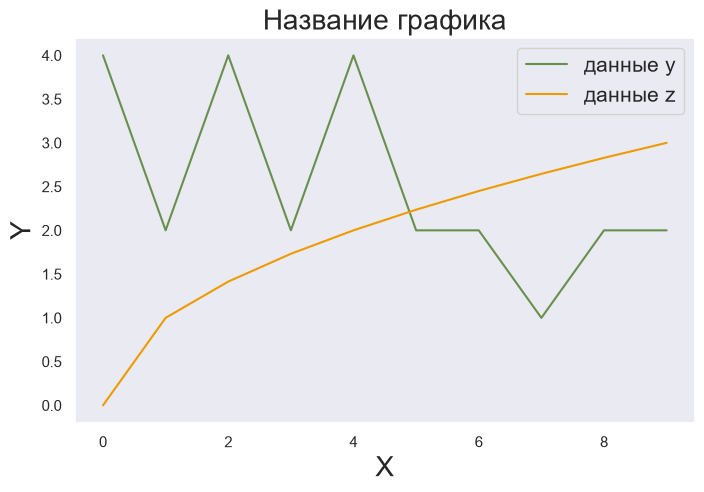

In [446]:
x = np.arange(10)
y = np.random.randint(1,5,size=10)
z = np.sqrt(x)

plt.figure(figsize=(8,5))
plt.plot(x,y, color="#68904D", label='данные y')
plt.plot(x,z, color="#EE9B01", label='данные z')

plt.legend(fontsize=15)
plt.title("Название графика", fontsize=20)

plt.xlabel("X",fontsize=20)
plt.ylabel("Y",fontsize=20)

# так можно ограничить координаты осей OX и OY
# plt.xlim([-5, 20])
# plt.ylim([-5,20])

plt.grid()
plt.show()

Также можно отрисовывать точки, не соединенные линиями. Это называется Scatter Plot

In [447]:
print(plt.style.available)
plt.style.use('dark_background')

['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


### Предобработка (очистка) данных

Очистка данных - это удаление или замена плохих данных в датасете.

Плохими данными могут быть:
* Пустые ячейки
* Данные в неправильном формате
* Неправильные данные
* Дубликаты

Мы можем вывести для каждого элемента данных, пропущен он или нет, с помощью метода .isna():

Cуммируем по оси 0, чтобы узнать количество пропущенных значений в каждом из столбцов:

In [448]:
df.isna().sum(axis=0)

PassengerId      0
Name             0
Survived         0
Pclass           0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Также для красоты и удобства можно визуализировать количество пропущенных значений следующим способом:

<BarContainer object of 12 artists>

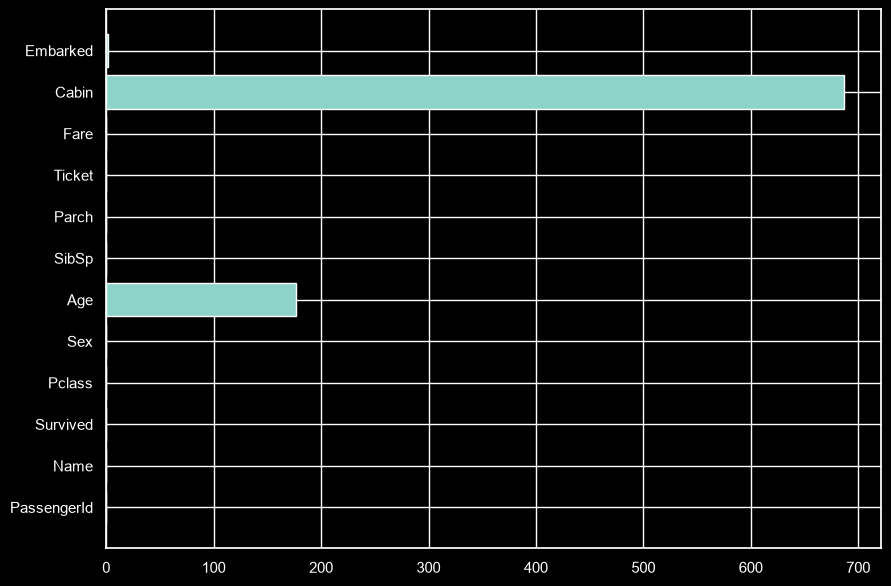

In [449]:
data = df.isna().sum()

plt.figure(figsize=(10,7))
plt.barh(data.index, data.values)

Давайте рассмотрим еще один способ визуализации — тепловую карту (heatmap). Ее мы построим при помощи библиотеки seaborn.


In [450]:
import seaborn as sns

<Axes: >

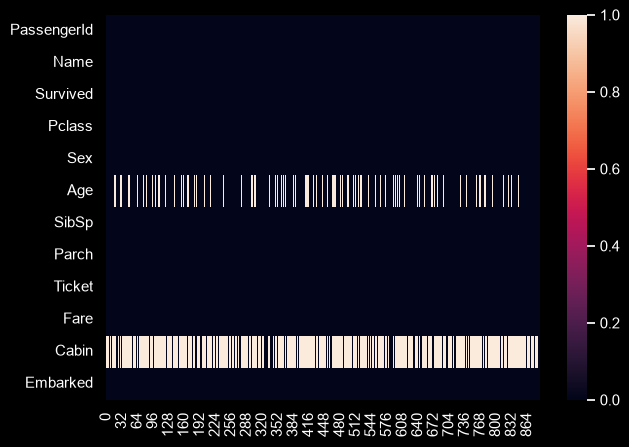

In [451]:
plt.figure(figsize=(7,5))
sns.heatmap(df.isna().T)

In [452]:
na_percentage = round((df['Cabin'].isna().sum() / len(df['Cabin'])) * 100, 3)
print(f'{na_percentage} % пропущенных данных у признакак Cabin')

77.104 % пропущенных данных у признакак Cabin


Что делать с пропущенными значениями признака? Можно их заполнить какими-нибудь статистиками

- **Мода** - значение изменяемого признака, которое встречается максимально часто.

- **Медиана** - значение признака, которое делит упорядоченное множество данных пополам.

- **Среднее** - среднее арифметическое, т.е. сумма всех значений признака, деленная на количество значений признака.

Если распределение симметрично, унимодально (имеет только одну моду) и не имеет заметных выбросов, то все три меры примерно дадут одинаковое значение. Если же ассиметрично или имеет заметные выбросы, лучше ориентироваться на моду или медиану.

Для числовых признаков часто используется медиана, для категориальных — мода.

In [453]:
df['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

<BarContainer object of 3 artists>

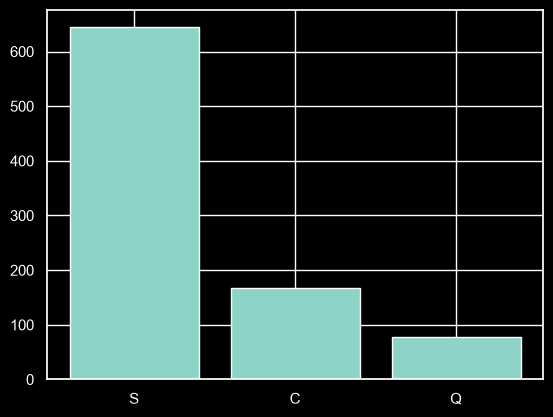

In [454]:
# Нарисуем столбчатую диаграмму Embarked признака
data = df['Embarked'].value_counts()

plt.bar(data.index, data.values)

Самое часто встречающееся значение (оно же мода этого признака) — S:

In [455]:
df['Embarked'].mode()

0    S
Name: Embarked, dtype: str

In [456]:
mean_Age = np.mean(df['Age'].dropna().values)
median_Age = np.quantile(df['Age'].dropna().values,q=0.5)
mode_Age = df['Age'].dropna().mode()[0]

mean_Age, median_Age, mode_Age

(np.float64(29.69911764705882), np.float64(28.0), np.float64(24.0))

Нарисуем распределение признака Age с его средним и медианой:

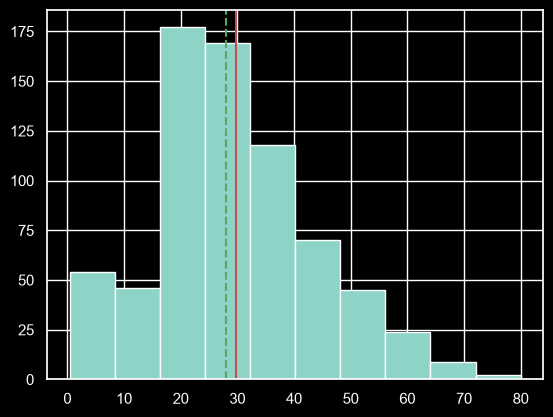

In [457]:
plt.hist(df['Age'])

plt.axvline(x=mean_Age, color='r', linestyle = '-', label='mean')
plt.axvline(x=median_Age, color='g', linestyle = '--', label='median')

plt.show()

Мы только что рассмотрели несколько способов визуализации информации о колонках датасета. Эту информацию можно использовать для заполнения пропсуков в данных. Но сейчас давайте просто удалим все строки с пропущенными значениями из нашего датасета.

In [458]:
# Удаляем все NaN
df.dropna(inplace=True)

# другие способы:
# df.fillna(0)
# df.fillna(df.mean())
# df[df.isna()] = df.median()

Проверяем, что пропущенных значений не осталось:

In [459]:
df.isna().sum()

PassengerId    0
Name           0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

###  Создание новых признаков

Давайте посмотрим на столбец Name наших данных:

In [460]:
df['Name']

1      Cumings, Mrs. John Bradley (Florence Briggs Th...
3           Futrelle, Mrs. Jacques Heath (Lily May Peel)
6                                McCarthy, Mr. Timothy J
10                       Sandstrom, Miss. Marguerite Rut
11                              Bonnell, Miss. Elizabeth
                             ...                        
871     Beckwith, Mrs. Richard Leonard (Sallie Monypeny)
872                             Carlsson, Mr. Frans Olof
879        Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)
887                         Graham, Miss. Margaret Edith
889                                Behr, Mr. Karl Howell
Name: Name, Length: 183, dtype: str

Name — колонка с именами пассажиров Титаника. Кажется, что эта колонка не очень информативна для определения того, выжил пассажир или нет. Единственное, что может быть информативным в этом признаке — это Title (Miss/Mr/Ms) пассажира. Поэтому прежде чем удалить эту колонку из данных, давайте проверим корреляцию между этим признаком и целевой переменной (колонкой Survived).

В ячейке ниже мы извлекаем признак Title с помощью регулярных выражений. Шаблон RegEx (\w+\.) ищет первое слово, заканчивающееся точкой, в признаке Name. Флаг expand=False возвращает DataFrame.

In [461]:
df['Title'] = df.Name.str.extract(' ([A-Za-z]+)\.', expand=False)

pd.crosstab(df['Title'], df['Sex'])

<>:1: SyntaxWarning: invalid escape sequence '\.'
<>:1: SyntaxWarning: invalid escape sequence '\.'
C:\Users\PC\AppData\Local\Temp\ipykernel_20000\3076444130.py:1: SyntaxWarning: invalid escape sequence '\.'
  df['Title'] = df.Name.str.extract(' ([A-Za-z]+)\.', expand=False)


Sex,female,male
Title,,
Capt,0,1
Col,0,1
Countess,1,0
Dr,1,2
Lady,1,0
Major,0,2
Master,0,7
Miss,44,0
Mlle,2,0


Мы видим, что есть некоторые титулы, которые встречаются нечасто. Давайте редкие титулы заменим на один класс, назовем его "Rare":

In [462]:
df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col',\
 	'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')

df['Title'] = df['Title'].replace('Mlle', 'Miss')
df['Title'] = df['Title'].replace('Ms', 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

In [463]:
df[['Title', 'Survived']].groupby(['Title'], as_index=False).mean()

,Title,Survived
0,Master,1.000000
1,Miss,0.934783
2,Mr,0.370370
3,Mrs,0.923077
4,Rare,0.700000


Зачем нужно создание новых признаков? Вот несколько причин:

1. Иногда создание новых признаков помогает улучшить обучение модели. Это может происходить, если признаки очень похожи друг на друга. Тогда их объединение может дать большую пользу, чем признаки по отдельности. Например, если несколько признаков в данных сильно скоррелированы, то это вредит обучению линейных моделей. И если эти признаки объединить в один, результат может улучшиться.
2. Объединение признаков в какой то один признак позволяет уменьшить вычислительную сложность, так как модели нужно смотреть не на несколько признаков, а только на один, который будет вбирать в себя все важное.
3. Это помогает в некоторых случаях понятнее интерпретировать результаты.

### Удаление ненужных столбцов

In [464]:
df.drop(columns=["Cabin", 'Name', 'Ticket'], inplace=True)

### Шаг 1. Анализ целевой переменной

Давайте посмотрим на распределение значений целевой переменной Survived:

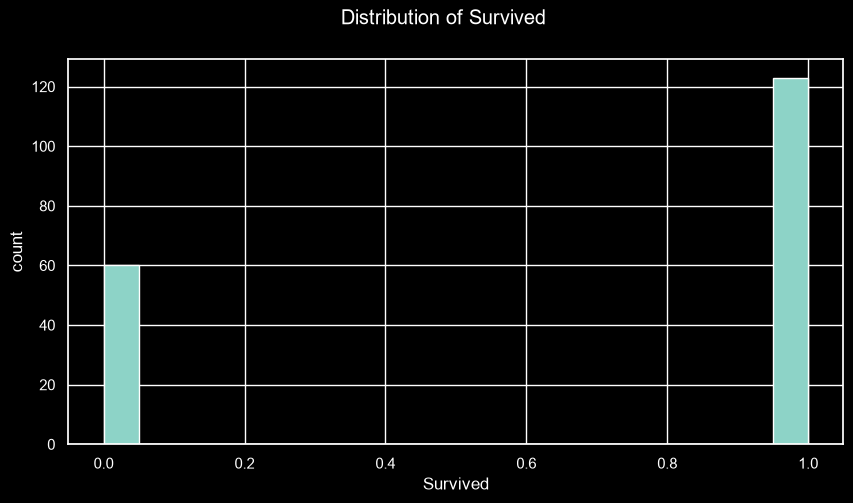

In [465]:
plt.figure(figsize = (10, 5))

df['Survived'].hist(density=False, bins=20)
plt.ylabel('count')
plt.xlabel('Survived')

plt.suptitle('Distribution of Survived')
plt.show()

Мы видим, что значения распределены не совсем ровно, но критичного перекоса тоже нет. Если значения целевой переменной несбалансированы (тогда говорят, что датасет несбалансирован), то нужны специальные методы для борьбы с дисбалансом.

### Шаг 2. Анализ признаков

#### Категориальные признаки

Заведем список категориальных колонок:

In [466]:
categorical_columns = ['Pclass', 'Sex', 'SibSp', 'Parch','Embarked', 'Title']
categorical_features = df[categorical_columns]

Найдем среди категориальных колонок те, значения в которых не числовые:

In [467]:
unprocessed_cat_features = categorical_features.select_dtypes(include=[object]).columns.tolist()
unprocessed_cat_features

C:\Users\PC\AppData\Local\Temp\ipykernel_20000\1742312485.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  unprocessed_cat_features = categorical_features.select_dtypes(include=[object]).columns.tolist()


['Sex', 'Embarked', 'Title']

**One-hot-encoding**

![alt text](image.png)

In [468]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(sparse_output=False)

one_hot_encoded = encoder.fit_transform(df[unprocessed_cat_features])
one_hot_df = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(unprocessed_cat_features), index=df.index)

In [469]:
df_encoded = pd.concat([df, one_hot_df], axis=1)

df_encoded = df_encoded.drop(unprocessed_cat_features, axis=1)
df_encoded

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
1,2,1,1,38.0,1,0,71.2833,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,4,1,1,35.0,1,0,53.1000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
6,7,0,1,54.0,0,0,51.8625,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
10,11,1,3,4.0,1,1,16.7000,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
11,12,1,1,58.0,0,0,26.5500,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871,872,1,1,47.0,1,1,52.5542,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
872,873,0,1,33.0,0,0,5.0000,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
879,880,1,1,56.0,0,1,83.1583,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
887,888,1,1,19.0,0,0,30.0000,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [470]:
one_hot = pd.get_dummies(df['Title'])
df_one_hot = pd.concat([df, one_hot], axis=1)
df_one_hot = df_one_hot.drop('Title', axis=1)

In [471]:
df_one_hot

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Master,Miss,Mr,Mrs,Rare
1,2,1,1,female,38.0,1,0,71.2833,C,False,False,False,True,False
3,4,1,1,female,35.0,1,0,53.1000,S,False,False,False,True,False
6,7,0,1,male,54.0,0,0,51.8625,S,False,False,True,False,False
10,11,1,3,female,4.0,1,1,16.7000,S,False,True,False,False,False
11,12,1,1,female,58.0,0,0,26.5500,S,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
871,872,1,1,female,47.0,1,1,52.5542,S,False,False,False,True,False
872,873,0,1,male,33.0,0,0,5.0000,S,False,False,True,False,False
879,880,1,1,female,56.0,0,1,83.1583,C,False,False,False,True,False
887,888,1,1,female,19.0,0,0,30.0000,S,False,True,False,False,False


**Label Encoding**

В этом случае каждому уникальному значению столбца присваивается уникальное целочисленное значение.

Это более простой метод кодирования, но он имеет недостаток. Дето в том, что, переводя категориальные признаки в числа, мы задаем на элементах подядок. Например, если у нас есть признак "регион проживания", в котором значения "Москва", "Воронеж" и "Саратов", то после Label Encoding у нас получатся значения 0, 1 и 2. 2 > 1 > 0, но для изначальных значений признаков ("Москва", "Воронеж" и "Саратов") подобного отношения не существует. Некоторые модели машинного обучения могут пользоваться тем, что на элементах задан порядок, и тогда они будут неверно обрабатывать наши категориальные переменные.

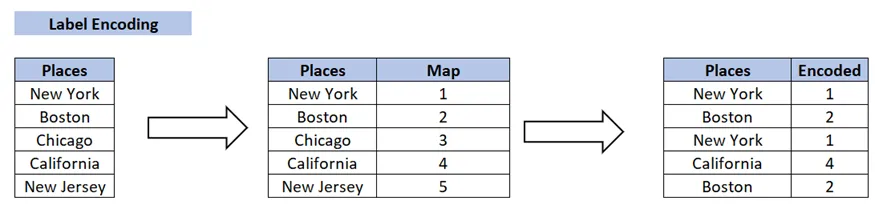

In [472]:
from sklearn.preprocessing import LabelEncoder

label_encoding = None # YOUR CODE

for column in unprocessed_cat_features:
  df[column] = None # YOUR CODE

#### Количественные признаки

Выделим числовые признаки нашего датасета:

In [473]:
numerical_columns = ['Age', 'Fare']

In [474]:
num_features = df[numerical_columns]

Посмотрим на распределения этих числовых признаков:

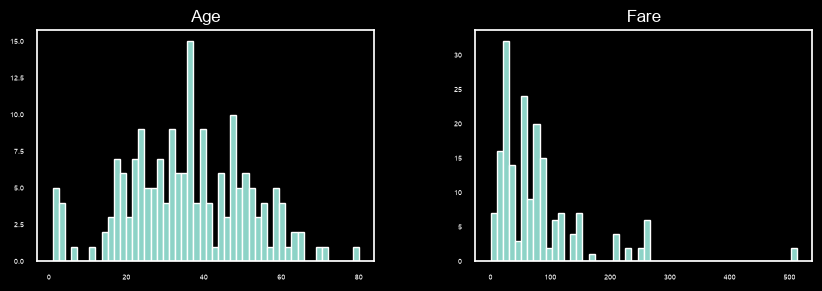

In [475]:
num_features.hist(figsize=(10, 3), bins=50,xlabelsize=5, ylabelsize=5, grid=False);

И еще построим все возможные графики взаимных распределений всех признаков между собой:

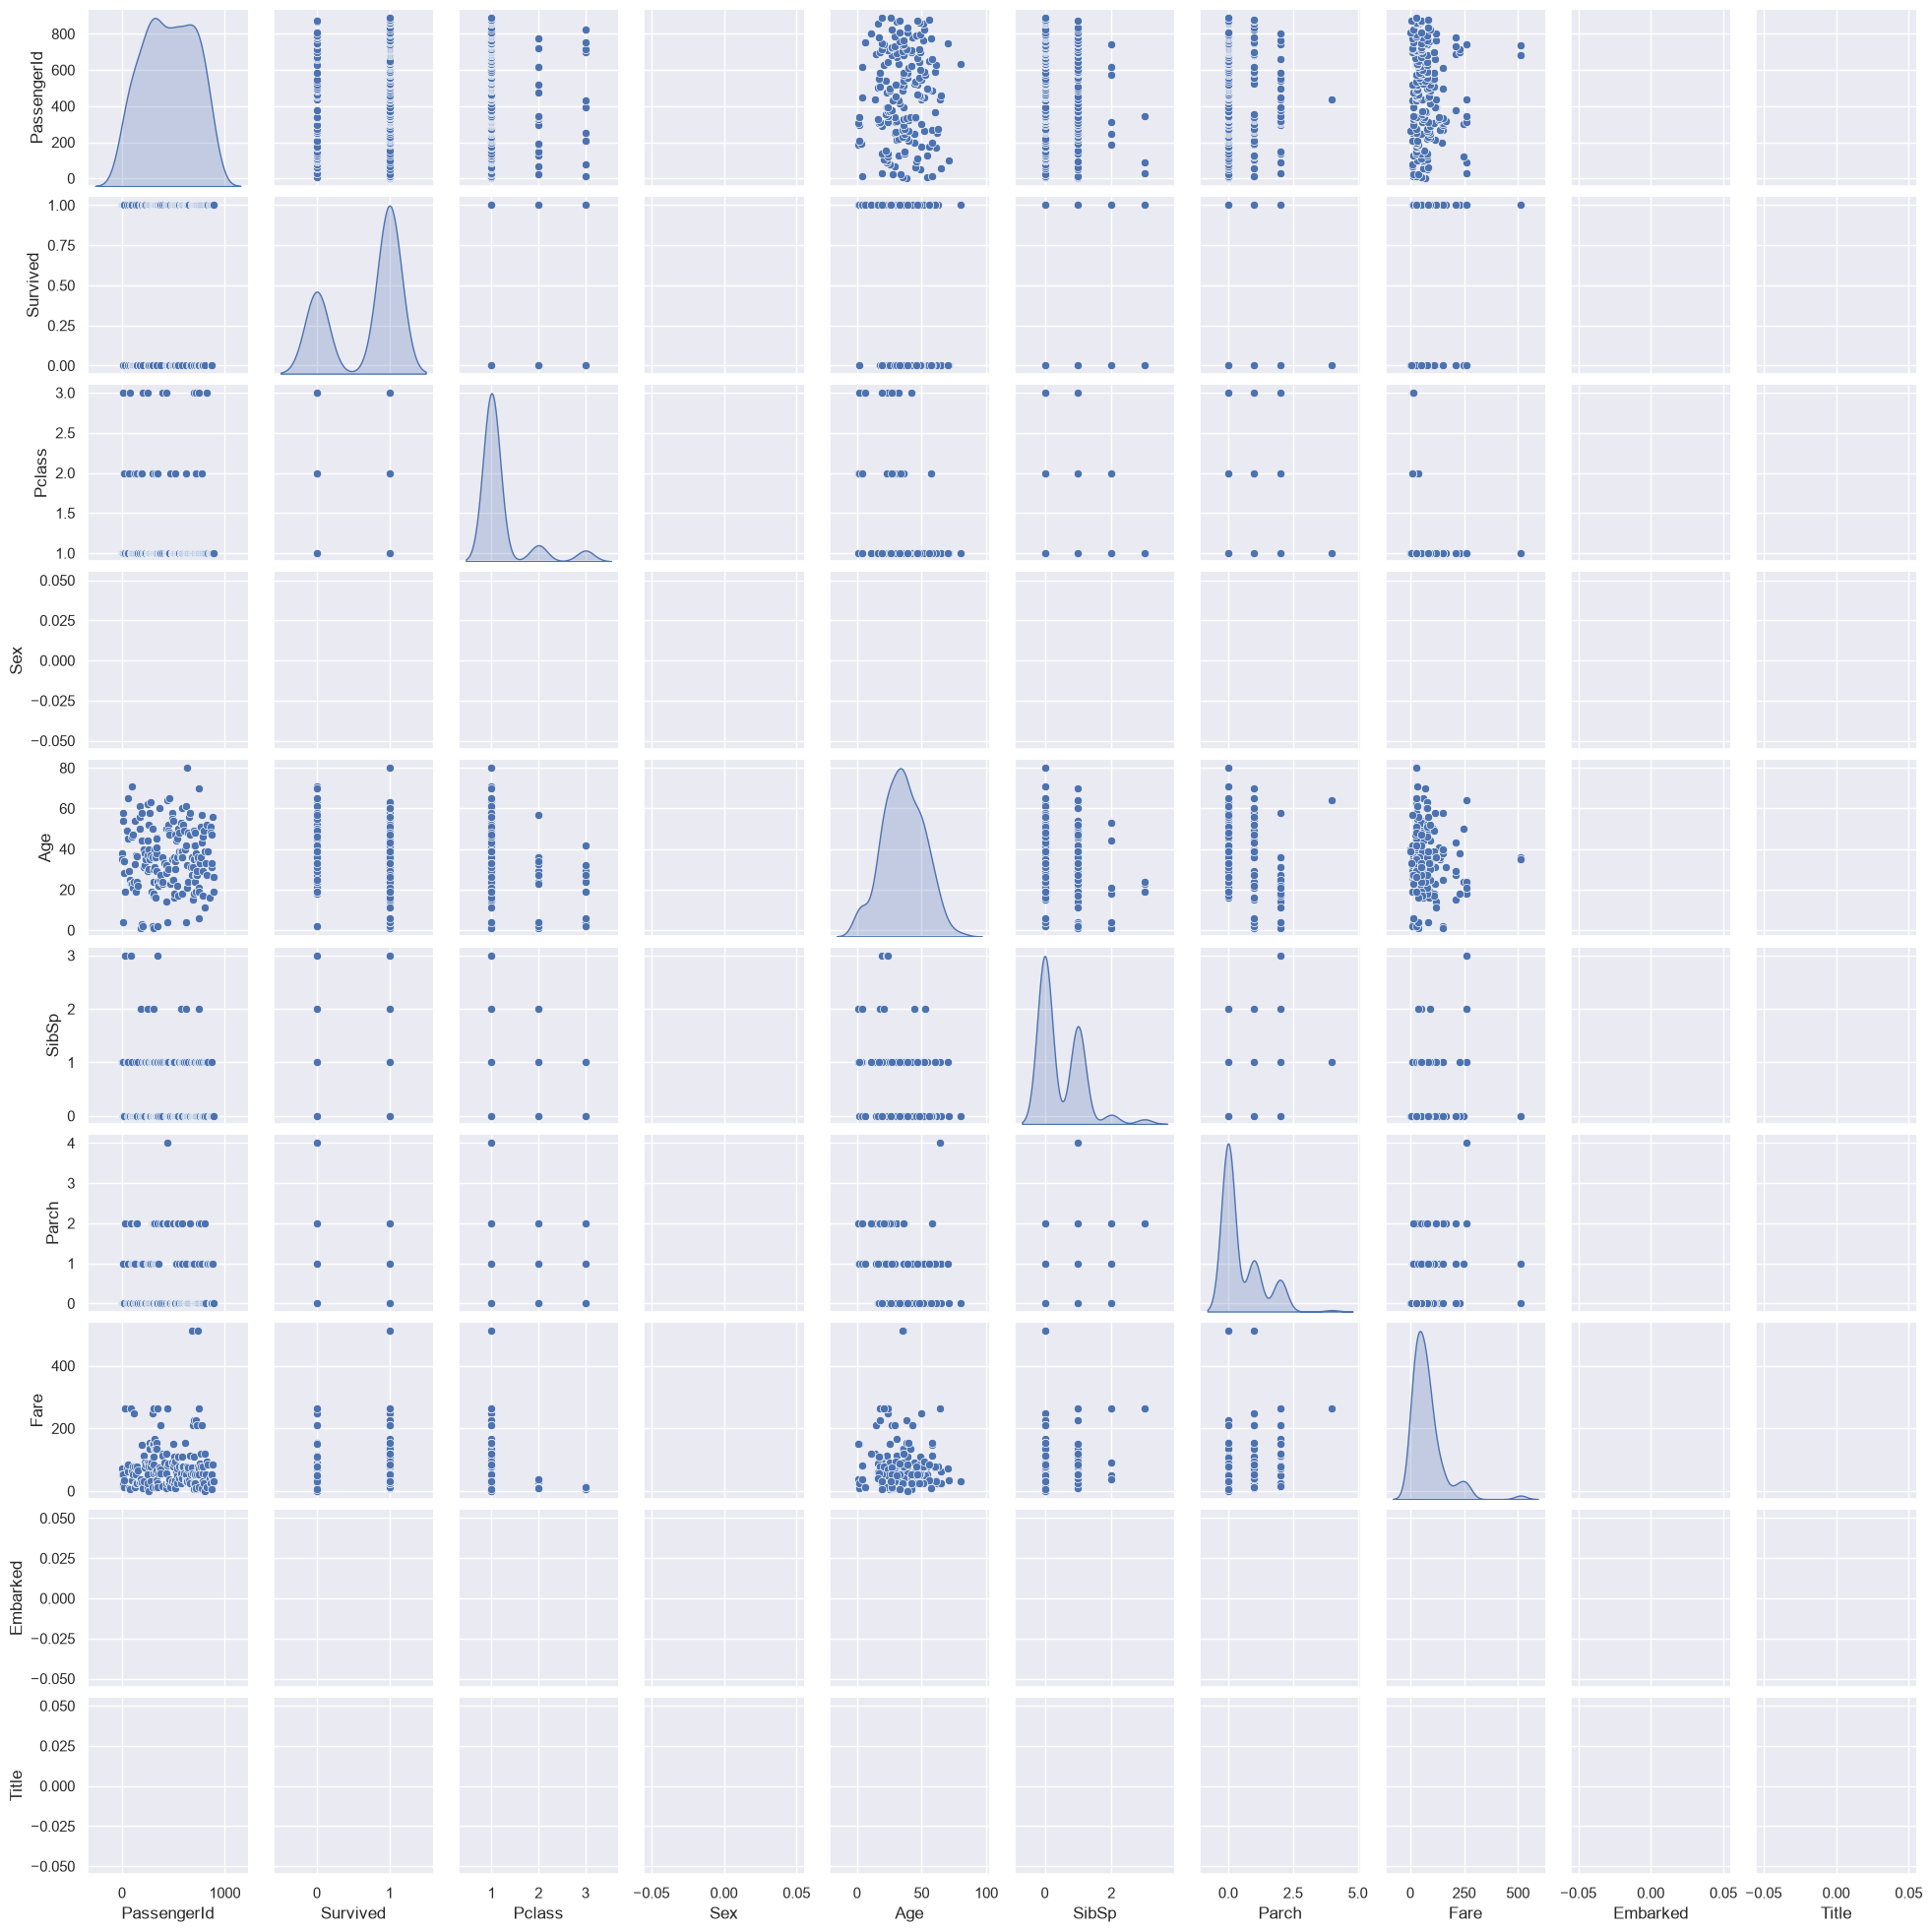

In [476]:
sns.set()
sns.pairplot(df, height = 2 ,kind ='scatter',diag_kind='kde')
plt.show()

Также давайте построим матрицу корреляций наших признаков.

Корреляция — мера линейной зависимости признаков друг от друга. Сильно скоррелированные признаки могут иметь негативный эффект на обучение линейных моделей. Если в датасете есть сильно скоррелированные признаки, и вы хотите использовать линейную модель машинного обучения, то от таких признаков нужно избавляться. Делать это можно несколькими способами:

1. Оставляя один из признаков
2. Соединив признак в один и создав новый признак
3. Сделать нелинейное преобразование признаков

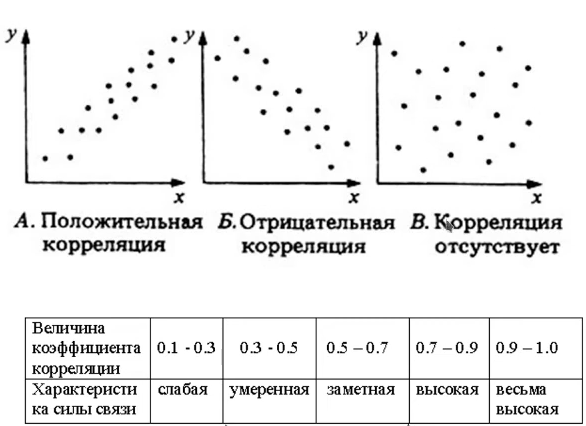

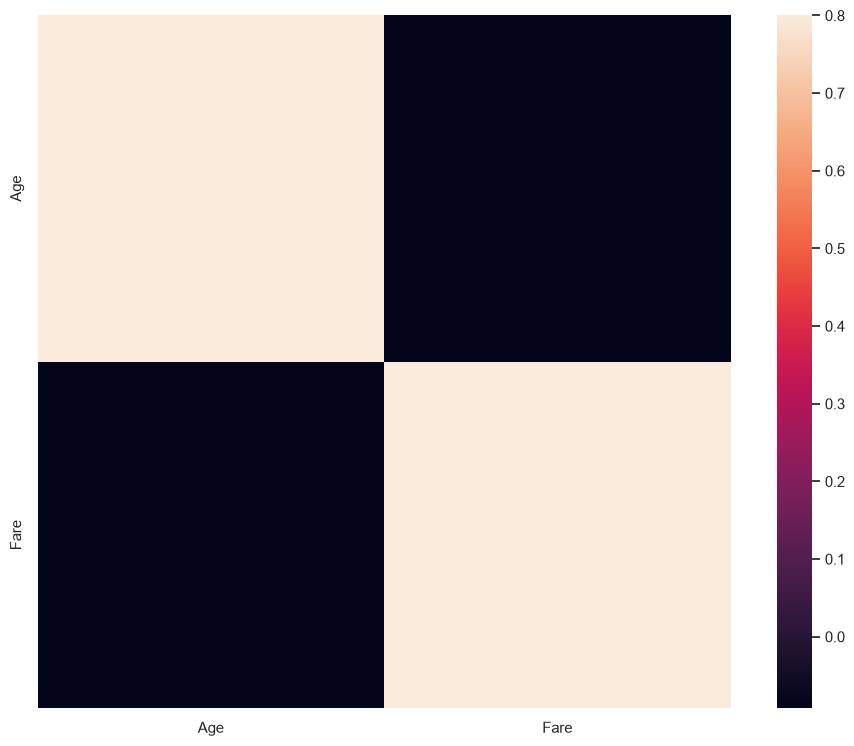

In [477]:
corrmat = df[numerical_columns].corr()
f, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corrmat, vmax=.8, square=True);

Сделаем картинку чуть красивее:

In [478]:
k = 10
cols = corrmat.nlargest(k, 'Survived')['Survived'].index
cm = np.corrcoef(df[cols].values.T)
sns.set(font_scale=1.25)
hm = sns.heatmap(cm, cbar=True, annot=True, square=True, fmt='.2f', annot_kws={'size': 10}, yticklabels=cols.values, xticklabels=cols.values)
plt.show()

KeyError: 'Survived'

Получается, когда мы смотрим на матрицу корреляций, нам важно следующее:
1. Хорошо, если целевая переменная и признак коррелируют. Значит, есть понятная зависимость между ответом и признаком;
2. Плохо, если признаки коррелируют между собой.


### Анализ влияния признаков на целевую переменную

Давайте теперь попробуем проанализировать наши данные в зависимости от нашей целевой переменной. Напомню, что в нашей задаче мы хотим предсказывать, выжил или не выжил человек на Титанике.

Попробуем ответить на следующие вопросы:
- Какие люди выживали чаще всего?
- Влияли ли пол и возраст на степень выживаемости на Титанике?
- Влияло ли наличие семьи на степень выживаемости?
- Есть ли зависимость стоимости билета от класса обслуживания?


Итак, какие люди выживали чаще всего?

Давайте нарисуем круговую диаграмму выживших в зависимости от класса обслуживания.

In [ ]:
df['Survived'].value_counts()

In [ ]:
data = df['Survived'].value_counts()

plt.pie(data, autopct='%1.1f%%')

plt.legend(['не выжили', 'выжили'], bbox_to_anchor=(0.8, 0.25))

plt.show()

In [ ]:
df[df['Pclass'] == 1]['Survived'].value_counts()

In [ ]:
data1 = df[df['Pclass'] == 1]['Survived'].value_counts()
data2 = df[df['Pclass'] == 2]['Survived'].value_counts()
data3 = df[df['Pclass'] == 3]['Survived'].value_counts()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(10,8))

ax1.pie(data1.values, labels=data1.index, autopct='%1.1f%%')
ax2.pie(data2.values, labels=data2.index, autopct='%1.1f%%')
ax3.pie(data3.values, labels=data3.index, autopct='%1.1f%%')

ax1.set_title("Pclass = 1")
ax2.set_title("Pclass = 2")
ax3.set_title("Pclass = 3")

fig.legend(
    ['не выжил', 'выжил'],
    loc='lower center',
    ncol=2,
    bbox_to_anchor=(0.5, 0.25)
)

plt.show()

Можно заметить, что люди с самым низким классом обслуживания в большей степени не выжили.

Посмотрим теперь, влияли ли пол и возраст на степень выживаемости или нет:

In [ ]:
plt.figure(figsize=(7, 5))

plt.hist(df['Age'][df['Survived'] == 0], alpha=0.5, label='не выжил')
plt.hist(df['Age'][df['Survived'] == 1], alpha=0.5, label='выжил')

plt.legend()

plt.show()

In [ ]:
# female - 0, male - 1
data_1 = df[df['Sex']== 1]['Survived'].value_counts().sort_values()
data_2 = df[df['Sex']== 0]['Survived'].value_counts().sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 8))

ax1.pie(data_1.values, labels=data_1.index, autopct='%1.1f%%', textprops={'fontsize': 10})
ax2.pie(data_2.values, labels=data_2.index, autopct='%1.1f%%', textprops={'fontsize': 10})

ax1.set_title('Survived (male)', fontsize=10)
ax2.set_title('Survived (female)', fontsize=10)

plt.legend(['не выжил', 'выжил'], fontsize=7)

plt.show()

Можно также отрисовать распределения признака возраста при помощи библиотеки seaborn.

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Age', kde=True, hue='Survived')
plt.title('Age Distribution by Survived')
plt.show()

Давайте теперь проверим, есть ли влияние стоимости билета на выживаемость:

In [ ]:
data1 = df['Fare'][df['Survived'] == 0]
data2 = df['Fare'][df['Survived'] == 1]
data1.head()

In [ ]:
# Строим боксплот

plt.figure(figsize=(10, 7))

plt.boxplot([data1, data2])

plt.title('Влияние стоимости билета на выживаемость')
plt.xlabel('Выжили')
plt.ylabel('Стоимость билета')
plt.xticks([1, 2], ['Нет', 'Да'])

plt.show()

Давайте поподробнее поймем, что это же такое боксплот.

Давайте сначала познакомимся с таким понятием как **квантиль распределения**. Квантили это такие значения признака, которые делят упорядоченные данные на некоторое число равных частей. К примеру, медиана делит наши данные на две равные части. Однако в статистике также часто используются квартили распределения. **Квартили распределения** это три точки, которые делят наши данные на 4 равные части.



        Q1-1.5IQR   Q1   median  Q3   Q3+1.5IQR
                      |-----:-----|
      o      |--------|     :     |--------|    o  o
                      |-----:-----|
    flier             <----------->            fliers
                          IQR

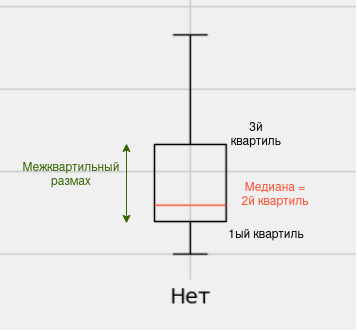

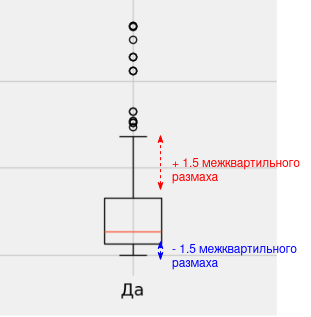

In [ ]:
first_quartile = np.quantile(df['Fare'].values, q=0.25)
third_quartile = np.quantile(df['Fare'].values, q=0.75)
print(f'1ый квартиль = {first_quartile}')
print(f'3ий квартиль = {third_quartile}')

Чем больше межквартильный размах, тем более велика вариативность нашего признака.

In [ ]:
plt.figure(figsize=(10, 7))

plt.boxplot([data1, data2], showfliers=False)

plt.title('Влияние стоимости билета на выживаемость')
plt.xlabel('Выжили')
plt.ylabel('Стоимость билета')
plt.xticks([1, 2], ['Нет', 'Да'])

plt.show()

## Подготовка данных для обучения модели

### Разделение на train/test

In [ ]:
X = df.drop(columns=['Survived']).values
y = df['Survived'].values

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True, stratify=y)

(!) Важно: когда вы делите на train\test в функции `train_test_split()` есть параметр `shuffle`, который перемешивает данные.

Перемешивание данных - это простая, но мощная техника, позволяющая обеспечить эффективное обучение и оценку моделей машинного обучения. Случайная перестановка точек данных позволяет избежать смещений, улучшить обобщение и сделать модели более надежными.

### Масштабирование данных

Зачем нам нужно масштабировать данные?

Приводить данные к одной шкале важно, когда мы сравниваем измерения в разных единицах. Переменные, измеренные в разных масштабах, не вносят одинакового вклада в анализ и в итоге могут создать байес.

Например, переменная, находящаяся в диапазоне от 0 до 1000, будет превосходить переменную, находящуюся в диапазоне от 0 до 1. Использование этих переменных без стандартизации даст переменной с большим диапазоном вес 1000 в анализе. Преобразование данных в сопоставимые шкалы может предотвратить эту проблему. Типичные процедуры стандартизации данных выравнивают диапазон и/или изменчивость данных.

Как мы говорили в лекции часто необходимо привести все признаки к одному масштабу. Для этого существует библиотека sklearn, которая предоставляет методы рескейлинга данных. На этом семинаре мы рассмотрим два основных: `StandardScaler()` и `MinMaxScaler()`. У каждого скейлера есть два метода: `.fit()` и `.transform()`.

`StandardScaler()` во время `.fit()` для каждого признака $x_i$ считает среднее $\mu_i$ и стандартное отклонение $\sigma_i$ на обучающем датасете. Во время `.transform()` к каждому признаку применяется:

$$\mathbf{x_i}^{\text{new}} = \frac{\mathbf{x_i} - \mu_i}{\sigma_i}$$


`MinMaxScaler()` во время `.fit()` для каждого признака $x_i$ считает минимум $x_{i, \text{min}}$ и максимум $x_{i, \text{max}}$ на обучающем датасете. Во время `.transform()` к каждому признаку применяется:

$$\mathbf{x_i}^{\text{new}} = \frac{\mathbf{x_i} - x_{i, \text{min}}}{x_{i, \text{max}} - x_{i, \text{min}}}$$

(!)Важно, чтобы статистика данных считалась только на обучающей выборке, т.е. на `X_train`, так как иначе, если мы будем считать статистику на всем датасете, модель будет уже иметь какую то информацию о тестовой выборке и предсказания будут нечестными, так как по сути вы ей дали подсказку.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print('До масштабирования: ',X_train.mean(axis=0))
print('После масштабирования: ',X_train_scaled.mean(axis=0))

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
print('До масштабирования: ',X_train.mean(axis=0))
print('После масштабирования: ',X_train_scaled.mean(axis=0))

## Небольшой пример: от нового датасета до линейной модели

Соберем знакомые шаги вместе. Возьмем [Diabetes из sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html): 442 наблюдения и 10 признаков. Цель `target` — числовой показатель прогрессирования заболевания через год; будем решать задачу регрессии.

Сохраним встроенный датасет в CSV и загрузим его через Pandas. Для своего файла достаточно заменить путь в `pd.read_csv()`. `scaled=False` позволяет получить признаки до масштабирования.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes

example_dir = Path('linear_model_example')
example_dir.mkdir(exist_ok=True)
diabetes_path = example_dir / 'diabetes.csv'

diabetes_dataset = load_diabetes(as_frame=True, scaled=False)
diabetes_dataset.frame.to_csv(diabetes_path, index=False)
diabetes_df = pd.read_csv(diabetes_path)
diabetes_df.head()

Посмотрим на размер таблицы, пропуски и основные статистики. Среди признаков есть возраст (`age`), индекс массы тела (`bmi`), давление (`bp`) и показатели анализа крови (`s1`–`s6`).

In [ ]:
print('Размер таблицы:', diabetes_df.shape)
print('Всего пропусков:', diabetes_df.isna().sum().sum())
diabetes_df.describe().round(2)

### Разделение и обучение

Отделим целевой столбец и оставим 20% строк для проверки. Масштабирование и модель объединим в `Pipeline`: при `.fit()` они обучатся только на train, а при `.predict()` к test применятся уже найденные параметры.

`LinearRegression` предсказывает число как сумму признаков с весами и свободного члена: `y ≈ w₀ + w₁x₁ + ... + wₙxₙ`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

diabetes_X = diabetes_df.drop(columns='target')
diabetes_y = diabetes_df['target']
diabetes_X_train, diabetes_X_test, diabetes_y_train, diabetes_y_test = train_test_split(
    diabetes_X, diabetes_y, test_size=0.2, random_state=42
)

diabetes_model = make_pipeline(StandardScaler(), LinearRegression())
diabetes_model.fit(diabetes_X_train, diabetes_y_train)
diabetes_prediction = diabetes_model.predict(diabetes_X_test)

Оценим предсказания на test. **MAE** — средняя абсолютная ошибка, меньше — лучше. **R²** равен 1 для идеального прогноза и может быть отрицательным. Для ориентира сравним MAE с простым прогнозом среднего значения train для всех строк.

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

diabetes_baseline = np.full(len(diabetes_y_test), diabetes_y_train.mean())
print(f'MAE модели: {mean_absolute_error(diabetes_y_test, diabetes_prediction):.2f}')
print(f'MAE прогноза средним: {mean_absolute_error(diabetes_y_test, diabetes_baseline):.2f}')
print(f'R² модели: {r2_score(diabetes_y_test, diabetes_prediction):.3f}')

### Посмотрим на признаки

Сравним корреляцию каждого признака с целью на train и коэффициенты модели. После `StandardScaler` коэффициент соответствует увеличению признака на одно стандартное отклонение при фиксированных остальных признаках.

Корреляция рассматривает признак отдельно, а коэффициент — вместе с остальными. При связанных признаках даже знаки могут различаться; модуль коэффициента не является универсальной мерой важности и не доказывает причинное влияние.

In [ ]:
diabetes_feature_analysis = pd.DataFrame({
    'correlation_with_target': diabetes_X_train.corrwith(diabetes_y_train),
    'coefficient': diabetes_model.named_steps['linearregression'].coef_,
})
diabetes_feature_analysis['abs_coefficient'] = diabetes_feature_analysis['coefficient'].abs()
diabetes_feature_analysis.sort_values('abs_coefficient', ascending=False).round(3)

### Сохраним и загрузим CSV

Запишем реальные значения и предсказания для test. Сохраним исходный номер строки в `row_id`, а `index=False` уберет лишний столбец индекса из CSV.

In [ ]:
diabetes_results = pd.DataFrame({
    'row_id': diabetes_X_test.index,
    'target': diabetes_y_test.to_numpy(),
    'prediction': diabetes_prediction,
}).sort_values('row_id')

prediction_path = example_dir / 'diabetes_predictions.csv'
diabetes_results.to_csv(prediction_path, index=False)
pd.read_csv(prediction_path).head()

# Итог

Короткая шпаргалка по основным функциям и методам занятия и тому что может пригодиться при выполнении дз

**NumPy — числовые массивы**

| Функции и методы | Назначение |
| --- | --- |
| `np.array()`, `np.zeros()`, `np.ones()` | Создание массивов |
| `np.arange()`, `np.linspace()` | Последовательность с заданным шагом или количеством точек |
| `.reshape()`, `.astype()`, `.copy()` | Изменение формы, типа и создание независимой копии |
| `np.where()`, `np.unique()` | Выбор значений по условию и поиск уникальных значений |
| `np.sum()`, `np.max()`, `np.mean()`, `np.median()`, `np.std()`, `np.quantile()` | Суммы, максимумы и основные статистики; `axis` задает ось вычислений |
| `np.sqrt()`, `np.exp()`, `np.log()` | Квадратный корень, экспонента и логарифм (точно пригодится для softmax и cross-entropy) |
| `np.argmin()`, `np.argmax()`, `np.argsort()` | Индексы минимума, максимума и индексы элементов в порядке сортировки |
| `np.clip()`, `np.floor()` | Ограничение диапазоном и округление вниз, к меньшему целому |
| `np.bincount()`, `np.add.at()` | Подсчёты и суммы по целым неотрицательным меткам; накопление по повторяющимся индексам, например для матрицы ошибок |
| `np.diag()`, `np.fill_diagonal()` | Извлечение или создание диагонали; заполнение диагонали матрицы на месте |
| `np.linalg.norm()`, `np.linalg.solve()`, `np.linalg.svd()` | Норма, решение системы уравнений, SVD |

Срезы `X[:, :2]`, индексация массивами `X[[0, 2]]` и булевы маски `X[mask]` позволяют выбирать данные без циклов. Для двумерного `X` запись `X[:, None, :]` добавляет ось: `(n, d)` превращается в `(n, 1, d)`. При агрегации `axis` задает ось, а `keepdims=True` сохраняет ее с размером 1 — это удобно для broadcasting.

**Pandas — таблицы и анализ данных**

| Функции и методы | Назначение |
| --- | --- |
| `pd.read_csv()`, `df.to_csv("answer.csv", index=False)` | Чтение CSV и сохранение без дополнительного столбца индекса |
| `pd.DataFrame()`, `.to_numpy()` | Создание таблицы ответа и преобразование данных в массив NumPy |
| `.head()`, `.info()`, `.describe()` | Просмотр строк, структуры таблицы и статистик |
| `.loc[...]`, `.iloc[...]` | Выбор данных по меткам или позициям |
| `.isna()`, `.dropna()`, `.fillna()` | Поиск, удаление и заполнение пропусков |
| `.count()`, `.nunique()`, `.value_counts()` | Число непропущенных значений, число уникальных значений и частоты |
| `.mean()`, `.median()`, `.std(ddof=0)`, `.sum()` | Статистики столбцов и групп; `ddof=0` задает деление на N при расчете дисперсии |
| `.groupby()`, `.agg()` | Группировка и вычисление статистик |
| `df.apply()` | Применение своей функции к столбцам (`axis=0`) или строкам (`axis=1`) |
| `.groupby(...).transform()` | Групповая статистика для каждой исходной строки: стандартизация и заполнение пропусков |
| `.sort_values()`, `.idxmax()` | Сортировка по столбцам; метка первого максимума в Series |
| `.merge(..., how="left")` | Объединение по ключу с сохранением строк левой таблицы, в том числе без совпадений справа |
| `.corr()`, `.corrwith()` | Корреляции между столбцами или с целевой переменной |

Выбор нескольких столбцов: `df[["a", "b"]]`; создание нового: `df["new"] = ...`. Условия объединяем через `&`, `|`, `~`, заключая каждое сравнение в скобки. Для ДЗ особенно полезны `sort_values()`, `transform()`, `merge()` и явный `ddof=0`: у Pandas по умолчанию `ddof=1`, у NumPy — `ddof=0`.

**Matplotlib и Seaborn — визуализация**

| Функции | Назначение |
| --- | --- |
| `plt.plot()`, `plt.bar()`, `plt.hist()`, `plt.boxplot()` | Линии, столбцы, гистограмма и боксплот |
| `plt.subplots()`, `plt.title()`, `plt.xlabel()`, `plt.legend()` | Размещение графиков, заголовок, подпись оси и легенда |
| `sns.heatmap()`, `sns.pairplot()` | Тепловая карта и попарные зависимости признаков |

**sklearn — подготовка данных и модель**

| Функции и методы | Назначение |
| --- | --- |
| `train_test_split()` | Разделение данных на train и test |
| `StandardScaler`, `MinMaxScaler`, `OneHotEncoder` | Масштабирование числовых признаков и кодирование категорий |
| `make_pipeline()`, `LinearRegression` | Объединение преобразований и модель линейной регрессии |
| `.fit()`, `.transform()`, `.predict()` | Обучение, преобразование данных и получение предсказаний |
| `mean_absolute_error()`, `r2_score()` | Оценка качества регрессии |

**Главное правило:** сначала разделяем данные на train/test; преобразования и модель обучаем на train, качество проверяем на test.
